In [1]:
%pip install -q lxml==6.1.3 kagglehub==1.0.3 ultralytics==8.4.215 imagehash==4.3.2

In [ ]:
import os, io, sys, json, time, random, shutil, hashlib, zipfile, platform
from pathlib import Path
import xml.etree.ElementTree as ET
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import torch
import kagglehub
import imagehash
import ultralytics
from ultralytics import YOLO, settings

settings.update({"mlflow": False})      

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

SMOKE_TEST = False                     
PREFIX = "smoke_" if SMOKE_TEST else ""

CLASS_DICT = {"stop": 0, "speedlimit": 1, "crosswalk": 2, "trafficlight": 3}
NAMES = {v: k for k, v in CLASS_DICT.items()}

OUT = Path("data/yolo").resolve()      
RESULTS = Path("results").resolve()
CONFIGS = Path("configs").resolve()
RESULTS.mkdir(exist_ok=True); CONFIGS.mkdir(exist_ok=True)

DEVICE_INFO = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("python", platform.python_version(), "| torch", torch.__version__, "| ultralytics", ultralytics.__version__)
print("device:", DEVICE_INFO)
if not torch.cuda.is_available():
    print("WARNING: no GPU found. Training will be very slow. Use Runtime -> Change runtime type -> T4 GPU.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
python 3.13.16 | torch 2.14.1+cu130 | ultralytics 8.4.215
device: Tesla T4


In [3]:
path = kagglehub.dataset_download("andrewmvd/road-sign-detection")
SRC = Path(path)
print("dataset folder:", SRC)
print(os.listdir(SRC))

100%|██████████| 218M/218M [00:03<00:00, 72.3MB/s]

Extracting files...


dataset folder: /root/.cache/kagglehub/datasets/andrewmvd/road-sign-detection/versions/1
['annotations', 'images']


In [4]:
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

def voc_to_yolo(xml_path):
    root = ET.parse(xml_path).getroot()
    w = int(root.find("size/width").text)
    h = int(root.find("size/height").text)
    lines = []
    for obj in root.findall("object"):
        cls = CLASS_DICT[obj.find("name").text.strip()]
        b = obj.find("bndbox")
        x1, y1 = float(b.find("xmin").text), float(b.find("ymin").text)
        x2, y2 = float(b.find("xmax").text), float(b.find("ymax").text)
        lines.append(f"{cls} {(x1+x2)/2/w:.6f} {(y1+y2)/2/h:.6f} {(x2-x1)/w:.6f} {(y2-y1)/h:.6f}")
    return lines

def split_and_convert(train_frac=TRAIN_FRAC, val_frac=VAL_FRAC, seed=SEED):
    if OUT.exists():
        shutil.rmtree(OUT)                                   # start clean so stale files never leak between splits
    stems = sorted(p.stem for p in (SRC / "annotations").glob("*.xml"))
    random.Random(seed).shuffle(stems)
    n = len(stems)
    t, v = int(n * train_frac), int(n * (train_frac + val_frac))
    splits = {"train": stems[:t], "val": stems[t:v], "test": stems[v:]}
    for split, names in splits.items():
        (OUT / "images" / split).mkdir(parents=True, exist_ok=True)
        (OUT / "labels" / split).mkdir(parents=True, exist_ok=True)
        for s in names:
            shutil.copy(SRC / "images" / f"{s}.png", OUT / "images" / split / f"{s}.png")
            (OUT / "labels" / split / f"{s}.txt").write_text("\n".join(voc_to_yolo(SRC / "annotations" / f"{s}.xml")))
        print(split, len(names), "images")

split_and_convert()

yaml_text = (f"path: {OUT.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
             + "".join(f"  {i}: {NAMES[i]}\n" for i in range(len(NAMES))))
DATA_YAML = OUT / "data.yaml"
DATA_YAML.write_text(yaml_text)
print(yaml_text)

train 613 images
val 132 images
test 132 images
path: /content/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: stop
  1: speedlimit
  2: crosswalk
  3: trafficlight



The conclusion of the code below is that there is no disbalance between test, train and val but there is disbalance between 4 classes. 545 images for speedlimit and 56 for stop sign in train set for instance. The model can just always predict(by memorizing, not by generalizing(learning)) speedlimit and still have a high accuracy for example.

In [ ]:
rows = []
for split in ["train", "val", "test"]:
    c, n_img = Counter(), 0
    for f in sorted((OUT / "labels" / split).glob("*.txt")):
        n_img += 1
        for line in f.read_text().splitlines():
            if line.strip():
                c[NAMES[int(line.split()[0])]] += 1
    row = {"split": split, "images": n_img, "objects": sum(c.values())}
    row.update({NAMES[i]: c[NAMES[i]] for i in range(len(NAMES))})
    rows.append(row)
stats = pd.DataFrame(rows)
stats.to_csv(RESULTS / "dataset_stats.csv", index=False)
stats

,split,images,objects,stop,speedlimit,crosswalk,trafficlight
0,train,613,877,56,545,147,129
1,val,132,174,21,114,24,15
2,test,132,193,14,124,29,26


2 groups of duplicates is found

In [ ]:
xml_stems = {p.stem for p in (SRC / "annotations").glob("*.xml")}
png_stems = {p.stem for p in (SRC / "images").glob("*.png")}
print("annotations without image:", sorted(xml_stems - png_stems) or "none")
print("images without annotation:", sorted(png_stems - xml_stems) or "none")

problems, md5 = [], {}
for split in ["train", "val", "test"]:
    for img in (OUT / "images" / split).glob("*.png"):
        lab = OUT / "labels" / split / f"{img.stem}.txt"
        if not lab.exists():
            problems.append((img.name, "no label file")); continue
        lines = [l.split() for l in lab.read_text().splitlines() if l.strip()]
        if not lines:
            problems.append((img.name, "empty label"))
        for parts in lines:
            c, cx, cy, w, h = int(parts[0]), *map(float, parts[1:])
            if not (0 <= c < len(NAMES) and w > 0 and h > 0
                    and cx - w/2 >= -1e-3 and cx + w/2 <= 1 + 1e-3
                    and cy - h/2 >= -1e-3 and cy + h/2 <= 1 + 1e-3):
                problems.append((img.name, f"bad box {parts}"))
        md5.setdefault(hashlib.md5(img.read_bytes()).hexdigest(), []).append((split, img.name))

exact_dups = [v for v in md5.values() if len(v) > 1]
print("label problems:", problems or "none")
print("exact duplicate groups:", exact_dups or "none")
print("exact duplicates spread over several splits:", [g for g in exact_dups if len({s for s, _ in g}) > 1] or "none")

hashes = [(s, p.name, imagehash.phash(Image.open(p)))
          for s in ["train", "val", "test"] for p in (OUT / "images" / s).glob("*.png")]
near_pairs = [(a[:2], b[:2], int(a[2] - b[2])) for i, a in enumerate(hashes)
              for b in hashes[i+1:] if a[0] != b[0] and a[2] - b[2] <= 4]
print(len(near_pairs), "near-duplicate pairs across different splits")
if near_pairs:
    print("WARNING: some near-duplicates cross splits, review them / regroup the split:", near_pairs[:10])

DUP_INFO = {"label_problems": len(problems), "exact_dup_groups": len(exact_dups),
            "exact_dup_groups_in_one_split": len([g for g in exact_dups if len({s for s, _ in g}) == 1]),
            "near_dup_pairs_across_splits": len(near_pairs)}
DUP_INFO

annotations without image: none
images without annotation: none
label problems: none
exact duplicate groups: [[('train', 'road147.png'), ('train', 'road145.png')], [('train', 'road48.png'), ('train', 'road42.png')]]
exact duplicates spread over several splits: none
0 near-duplicate pairs across different splits


{'label_problems': 0,
 'exact_dup_groups': 2,
 'exact_dup_groups_in_one_split': 2,
 'near_dup_pairs_across_splits': 0}

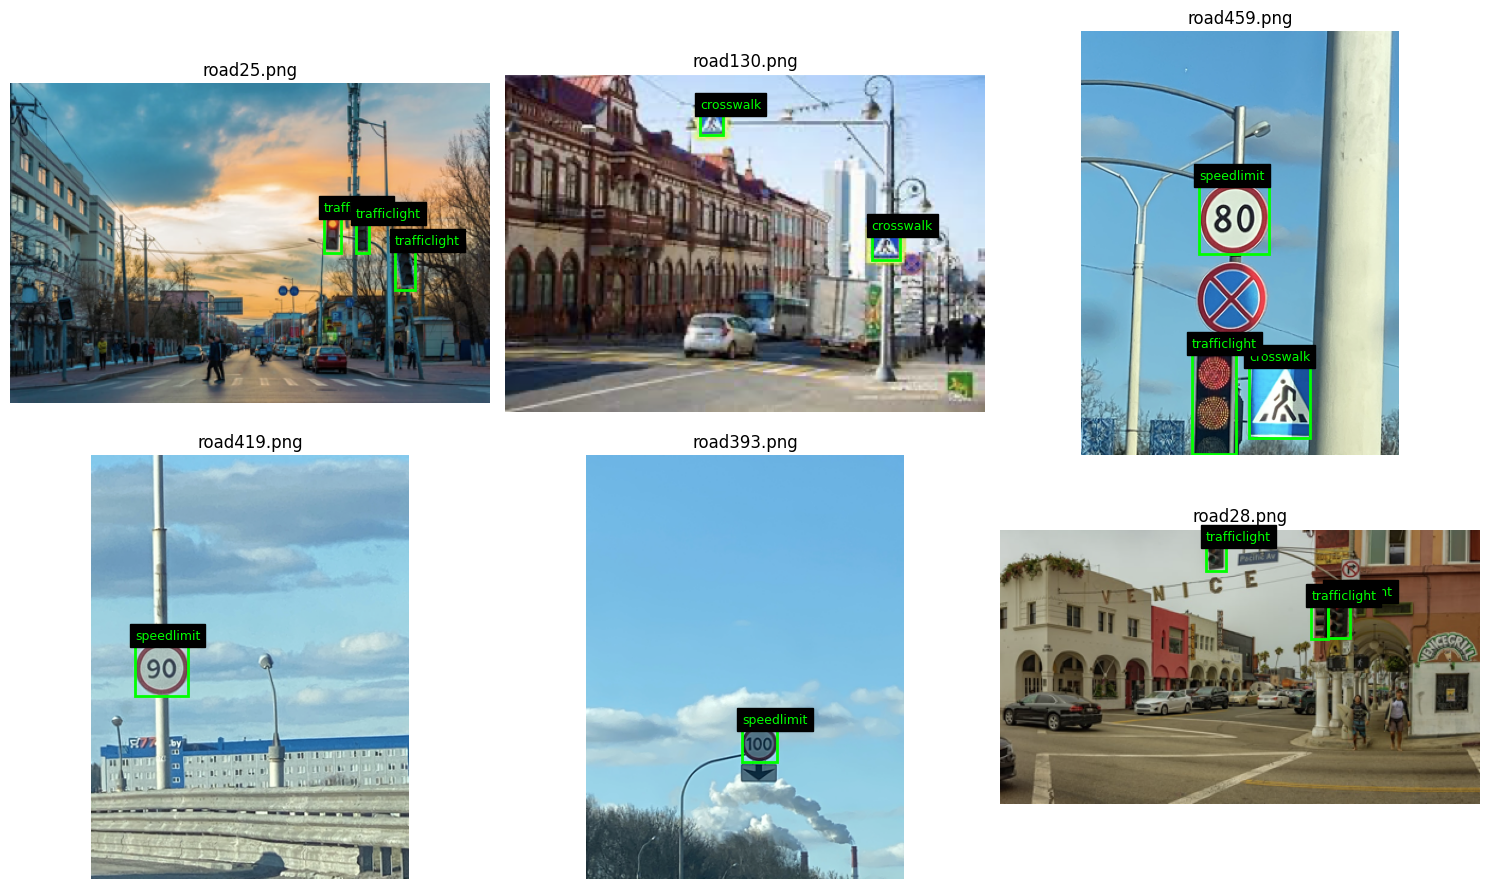

In [7]:
def draw_gt(ax, img_path, label_path, color="lime"):
    im = Image.open(img_path); W, H = im.size
    ax.imshow(im); ax.axis("off")
    for l in label_path.read_text().splitlines():
        if not l.strip():
            continue
        parts = l.split()
        c = int(parts[0]); cx, cy, w, h = map(float, parts[1:])
        x, y = (cx - w/2) * W, (cy - h/2) * H
        ax.add_patch(patches.Rectangle((x, y), w*W, h*H, fill=False, edgecolor=color, linewidth=2))
        ax.text(x, max(y - 3, 8), NAMES[c], color=color, backgroundcolor="black", fontsize=9)

def show_gt(split="train", k=6):
    imgs = sorted((OUT / "images" / split).glob("*.png"))
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, p in zip(axes.ravel(), random.Random(SEED).sample(imgs, k)):
        draw_gt(ax, p, OUT / "labels" / split / f"{p.stem}.txt")
        ax.set_title(p.name)
    plt.tight_layout()
    plt.savefig(RESULTS / "gt_examples.png", dpi=120)
    plt.show()

show_gt()

In [ ]:
WEIGHTS = "yolo26n.pt"                  # same initial checkpoint for BOTH runs
try:
    YOLO(WEIGHTS)
except Exception as e:
    print("Could not load", WEIGHTS, "->", e, "\nFalling back to yolo11n.pt")
    WEIGHTS = "yolo11n.pt"
print("initial weights:", WEIGHTS)

BASE_CFG = dict(
    data=str(DATA_YAML), imgsz=640, batch=16, epochs=(1 if SMOKE_TEST else 30),
    optimizer="AdamW", lr0=0.001,      
    seed=SEED, workers=2, cache=True,
    project=str(RESULTS), exist_ok=True,
)
if SMOKE_TEST:
    BASE_CFG["fraction"] = 0.1

def run_info_path(name):
    return RESULTS / name / "run_info.json"

def load_info(name):
    return json.loads(run_info_path(name).read_text())

def train_run(name, **overrides):
    name = PREFIX + name
    best = RESULTS / name / "weights" / "best.pt"
    if best.exists() and run_info_path(name).exists():
        print(f"{name}: finished run found, skipping training (delete results/{name} to retrain)")
        return name
    cfg = {**BASE_CFG, **overrides, "name": name}
    t0 = time.time()
    YOLO(WEIGHTS).train(**cfg)
    minutes = round((time.time() - t0) / 60, 2)
    info = dict(name=name, framework=f"ultralytics {ultralytics.__version__}", torch=torch.__version__,
                python=platform.python_version(), device=DEVICE_INFO, initial_weights=WEIGHTS,
                train_min=minutes, cfg=cfg, changed_vs_baseline=overrides)
    run_info_path(name).write_text(json.dumps(info, indent=2, default=str))
    print(f"{name}: trained in {minutes} min")
    return name

RUN1 = train_run("run1_baseline")
pd.Series(load_info(RUN1)["cfg"])

initial weights: yolo26n.pt
New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train,

,0
data,/content/data/yolo/data.yaml
imgsz,640
batch,16
epochs,30
optimizer,AdamW
lr0,0.001
seed,42
workers,2
cache,True
project,/content/results


In [ ]:
HYPOTHESIS = ("Reducing the input resolution from 640 to 320 will make training faster but will lower recall and "
              "mAP@0.50, especially for small objects such as traffic lights, because they keep only a few pixels "
              "after downscaling.")
CHANGE = {"imgsz": 320}                 

RUN2 = train_run("run2_experiment", **CHANGE)
pd.Series(load_info(RUN2)["cfg"])

New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=

,0
data,/content/data/yolo/data.yaml
imgsz,320
batch,16
epochs,30
optimizer,AdamW
lr0,0.001
seed,42
workers,2
cache,True
project,/content/results


In [10]:
EVAL_CONF, EVAL_IOU = 0.001, 0.7

def evaluate(name, split, conf=EVAL_CONF, iou=EVAL_IOU, plots=False):
    info = load_info(name)
    best = RESULTS / name / "weights" / "best.pt"
    return YOLO(str(best)).val(data=str(DATA_YAML), split=split, imgsz=info["cfg"]["imgsz"], conf=conf, iou=iou,
                               plots=plots, verbose=False, project=str(RESULTS),
                               name=f"{name}_eval_{split}", exist_ok=True)

rows = []
for run in [RUN1, RUN2]:
    info = load_info(run)
    m = evaluate(run, "val")
    changed = ", ".join(f"{k}={v}" for k, v in info["changed_vs_baseline"].items()) or "none (baseline)"
    rows.append({"run": run, "changed setting": changed, "precision": round(float(m.box.mp), 3),
                 "recall": round(float(m.box.mr), 3), "mAP@0.50": round(float(m.box.map50), 3),
                 "train time (min)": info["train_min"]})
comparison = pd.DataFrame(rows)
comparison.to_csv(RESULTS / "comparison_val.csv", index=False)

FINAL = comparison.sort_values("mAP@0.50", ascending=False).iloc[0]["run"]
print("final run chosen by validation mAP@0.50:", FINAL)
comparison

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4459.8±652.4 MB/s, size: 210.9 KB)
val: Scanning /content/data/yolo/labels/val.cache... 132 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 132/132 55.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 5.0it/s 1.8s
                   all        132        174      0.981      0.877      0.925      0.794
Speed: 1.1ms preprocess, 4.1ms inference, 0.0ms loss, 1.9ms postprocess per image
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4520.1±1131.0 MB/s, size: 341.4 KB)
val: Scanning /content/data/yolo/labels/val.cache... 132 images, 0 

,run,changed setting,precision,recall,mAP@0.50,train time (min)
0,run1_baseline,none (baseline),0.981,0.877,0.925,5.40
1,run2_experiment,imgsz=320,0.934,0.900,0.930,3.67


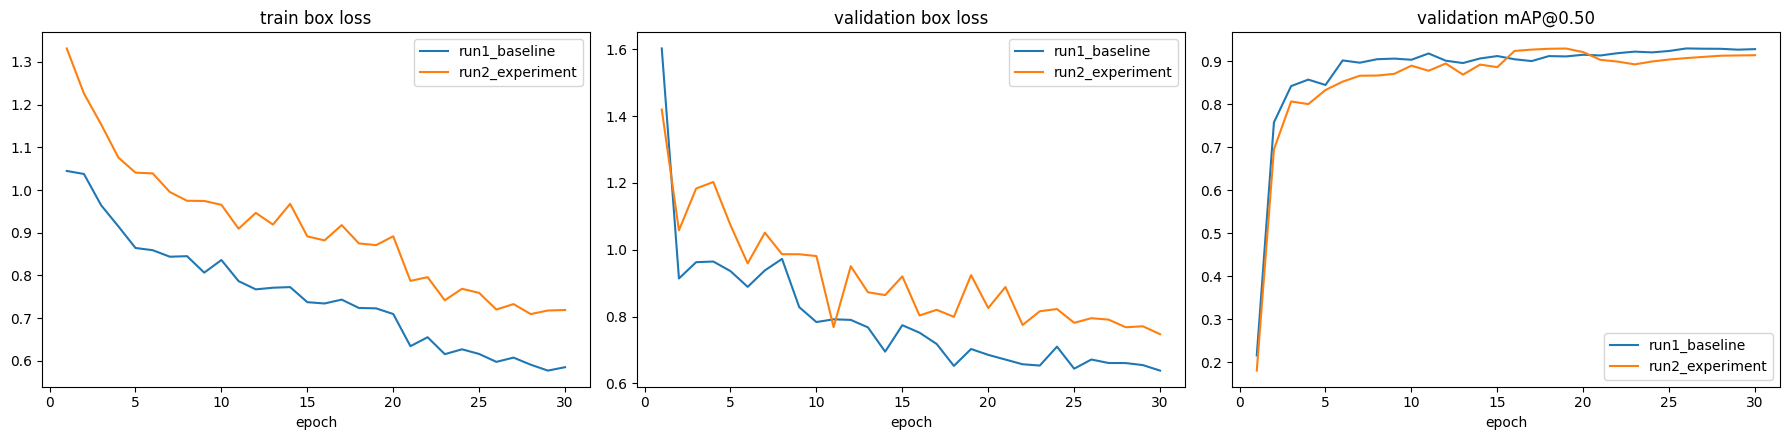

In [ ]:
def find_col(df, key):
    return next((c for c in df.columns if key in c), None)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for run in [RUN1, RUN2]:
    df = pd.read_csv(RESULTS / run / "results.csv"); df.columns = df.columns.str.strip()
    ep = df[find_col(df, "epoch")]
    for ax, key, title in zip(axes, ["train/box_loss", "val/box_loss", "mAP50(B)"],
                              ["train box loss", "validation box loss", "validation mAP@0.50"]):
        col = find_col(df, key)
        if col:
            ax.plot(ep, df[col], label=run); ax.set_title(title); ax.set_xlabel("epoch")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / "learning_curves_comparison.png", dpi=120)
plt.show()

In [12]:
final_info = load_info(FINAL)
FINAL_IMGSZ = final_info["cfg"]["imgsz"]
FINAL_BEST = RESULTS / FINAL / "weights" / "best.pt"

m_test = evaluate(FINAL, "test", plots=True)
test_overall = {"run": FINAL, "precision": round(float(m_test.box.mp), 3), "recall": round(float(m_test.box.mr), 3),
                "mAP@0.50": round(float(m_test.box.map50), 3), "conf": EVAL_CONF, "IoU (NMS)": EVAL_IOU,
                "imgsz": FINAL_IMGSZ}
display(pd.DataFrame([test_overall]))

per_class = pd.DataFrame([{"class": m_test.names[int(ci)], "precision": round(float(m_test.box.p[i]), 3),
                           "recall": round(float(m_test.box.r[i]), 3), "mAP@0.50": round(float(m_test.box.ap50[i]), 3)}
                          for i, ci in enumerate(m_test.box.ap_class_index)])
per_class.to_csv(RESULTS / "test_per_class.csv", index=False)
pd.DataFrame([test_overall]).to_csv(RESULTS / "test_overall.csv", index=False)
per_class

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2929.8±986.6 MB/s, size: 208.4 KB)
val: Scanning /content/data/yolo/labels/test... 132 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 132/132 1.0Kit/s 0.1s
val: New cache created: /content/data/yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 4.0it/s 2.3s
                   all        132        193      0.905      0.845      0.862      0.692
Speed: 0.4ms preprocess, 3.2ms inference, 0.0ms loss, 2.9ms postprocess per image
Results saved to /content/results/run2_experiment_eval_test


,run,precision,recall,mAP@0.50,conf,IoU (NMS),imgsz
0,run2_experiment,0.905,0.845,0.862,0.001,0.7,320


,class,precision,recall,mAP@0.50
0,stop,0.983,1.000,0.995
1,speedlimit,0.984,0.970,0.985
2,crosswalk,0.951,0.862,0.900
3,trafficlight,0.703,0.547,0.569


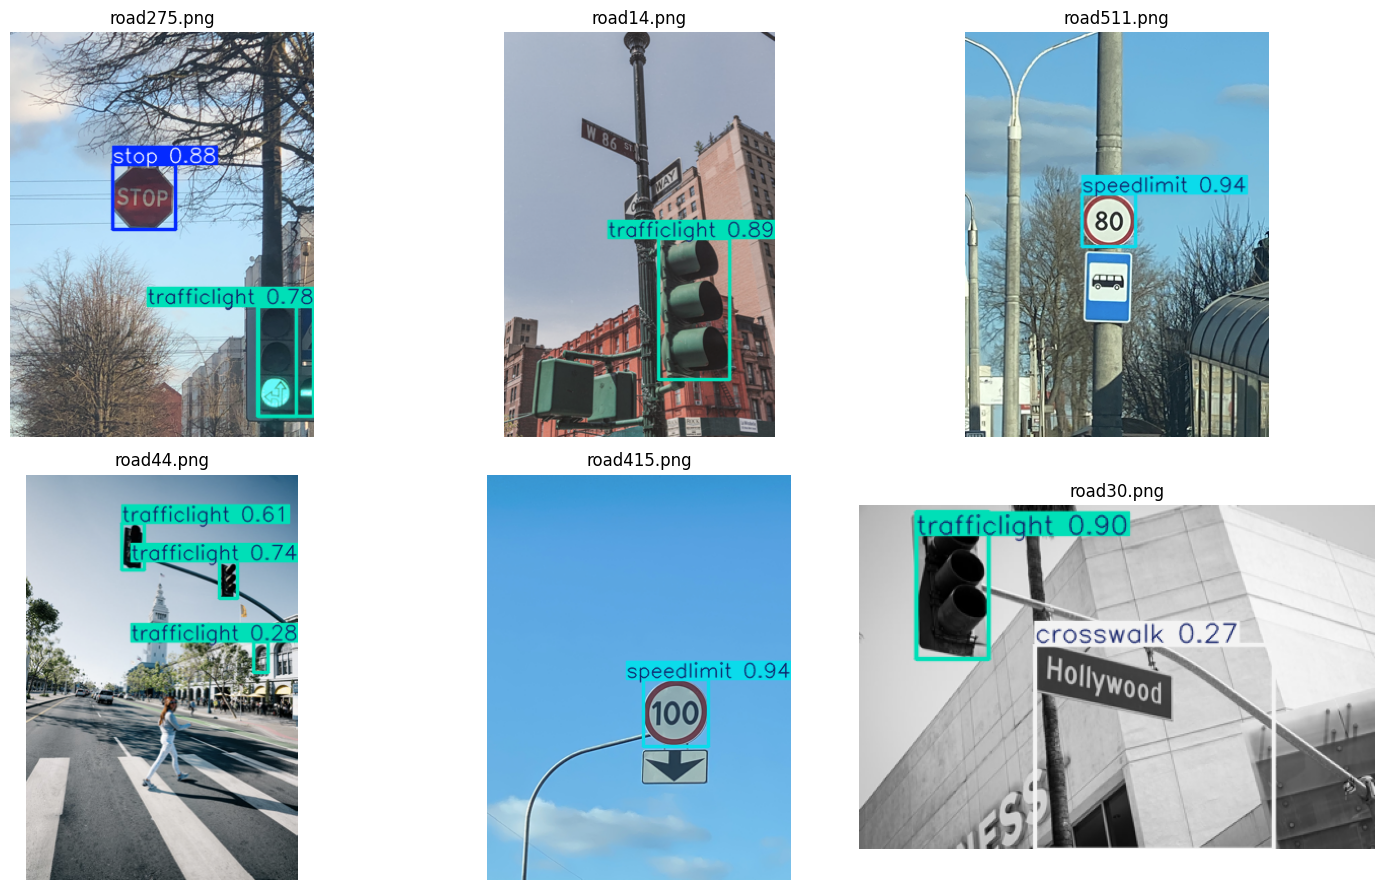

In [13]:
# test predictions with class names and confidence scores
PRED_CONF = 0.25
final_model = YOLO(str(FINAL_BEST))
test_paths = sorted((OUT / "images" / "test").glob("*.png"))
sample = random.Random(SEED).sample(test_paths, 6)
preds = final_model.predict([str(p) for p in sample], imgsz=FINAL_IMGSZ, conf=PRED_CONF, iou=EVAL_IOU, verbose=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, r in zip(axes.ravel(), preds):
    ax.imshow(r.plot()[:, :, ::-1])             # plot() returns BGR -> convert to RGB
    ax.set_title(Path(r.path).name); ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "test_predictions.png", dpi=120)
plt.show()

test images with at least one error: 27 of 132
totals: {'missed': 16, 'false_det': 19, 'wrong_cls': 0}


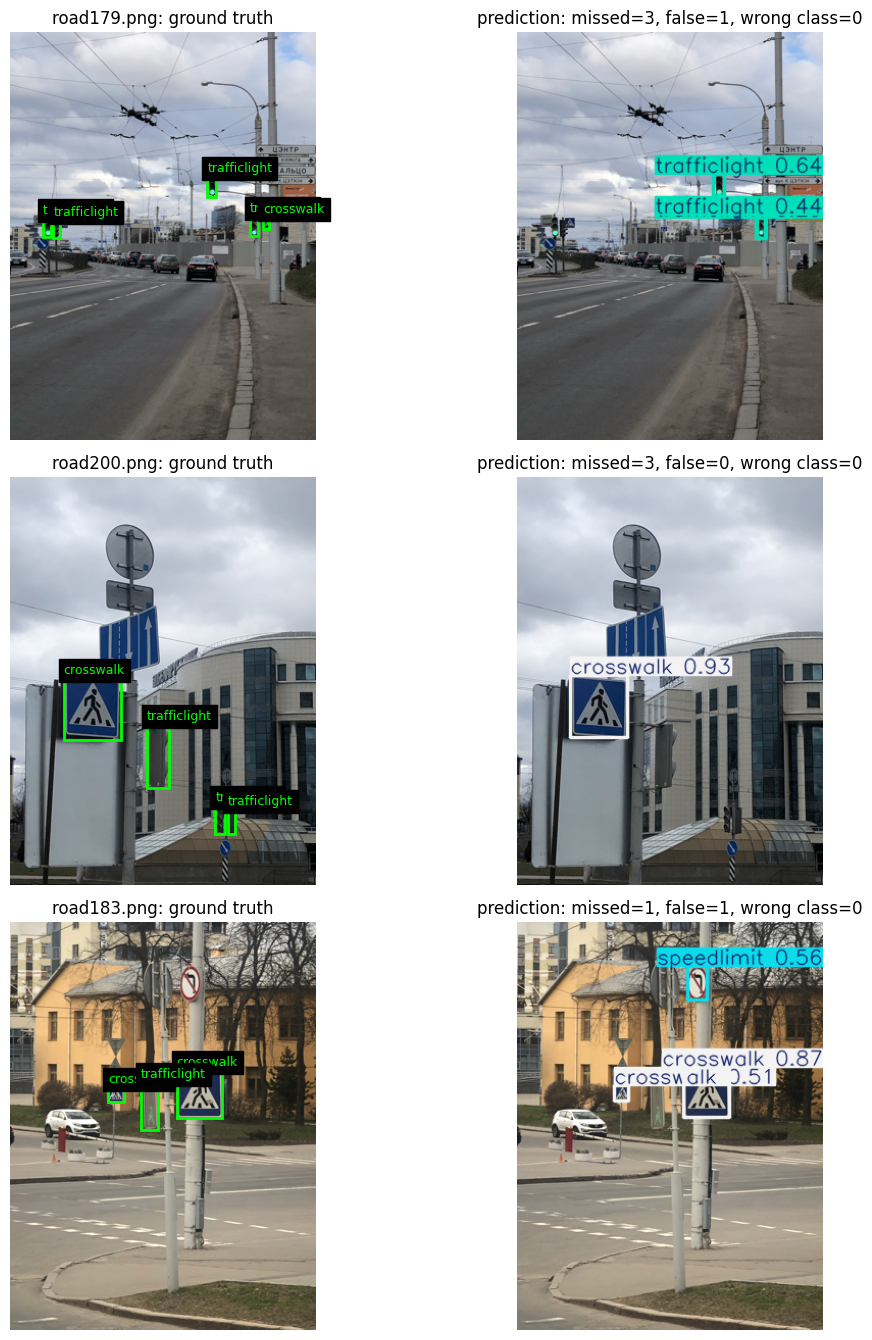

In [14]:
from torchvision.ops import box_iou

def analyze(res, label_path):
    H, W = res.orig_shape
    gt_boxes, gt_cls = [], []
    for l in label_path.read_text().splitlines():
        if not l.strip():
            continue
        parts = l.split()
        c = int(parts[0]); cx, cy, w, h = map(float, parts[1:])
        gt_boxes.append([(cx - w/2) * W, (cy - h/2) * H, (cx + w/2) * W, (cy + h/2) * H]); gt_cls.append(c)
    pb = res.boxes.xyxy.cpu(); pc = res.boxes.cls.int().tolist(); pf = res.boxes.conf.tolist()
    matched, fp, wrong = set(), 0, 0
    if len(pc) and gt_boxes:
        ious = box_iou(pb, torch.tensor(gt_boxes))
    for i in sorted(range(len(pc)), key=lambda k: -pf[k]):
        if not gt_boxes:
            fp += 1; continue
        cands = [(ious[i, j].item(), j) for j in range(len(gt_boxes)) if j not in matched and ious[i, j] >= 0.5]
        same = [(v, j) for v, j in cands if gt_cls[j] == pc[i]]
        if same:
            matched.add(max(same)[1])
        elif cands:
            wrong += 1; matched.add(max(cands)[1])
        else:
            fp += 1
    return {"missed": len(gt_boxes) - len(matched), "false_det": fp, "wrong_cls": wrong}

all_preds = final_model.predict([str(p) for p in test_paths], imgsz=FINAL_IMGSZ, conf=PRED_CONF, iou=EVAL_IOU, verbose=False)
fail_rows = []
for p, r in zip(test_paths, all_preds):
    d = analyze(r, OUT / "labels" / "test" / f"{p.stem}.txt")
    d.update(image=p.name, errors=sum(d.values())); fail_rows.append(d)
fail_df = pd.DataFrame(fail_rows).sort_values("errors", ascending=False)
print("test images with at least one error:", int((fail_df.errors > 0).sum()), "of", len(fail_df))
print("totals:", fail_df[["missed", "false_det", "wrong_cls"]].sum().to_dict())
fail_df.to_csv(RESULTS / "test_failures.csv", index=False)

worst = fail_df[fail_df.errors > 0].head(3)
if len(worst) < 3:
    print("Fewer than three failures occurred: discuss the most challenging test examples instead.")
fig, axes = plt.subplots(len(worst), 2, figsize=(12, 4.5 * max(len(worst), 1)), squeeze=False)
for row, (_, rec) in zip(axes, worst.iterrows()):
    p = OUT / "images" / "test" / rec["image"]
    draw_gt(row[0], p, OUT / "labels" / "test" / f"{p.stem}.txt")
    row[0].set_title(f"{rec['image']}: ground truth")
    row[1].imshow(all_preds[test_paths.index(p)].plot()[:, :, ::-1]); row[1].axis("off")
    row[1].set_title(f"prediction: missed={rec['missed']}, false={rec['false_det']}, wrong class={rec['wrong_cls']}")
plt.tight_layout()
plt.savefig(RESULTS / "failure_cases.png", dpi=120)
plt.show()

In [15]:
# requirements.txt, .gitignore, configs
Path("requirements.txt").write_text(
    "# versions used for the reported results (torch, numpy, pandas, matplotlib come preinstalled in Colab;\n"
    f"# torch {torch.__version__} was used, exact versions are also stored in results/*/run_info.json)\n"
    "ultralytics==8.4.215\nkagglehub==1.0.3\nlxml==6.1.3\nimagehash==4.3.2\n")

Path(".gitignore").write_text(
    "# dataset is re-created by the notebook (kagglehub + seeded split)\ndata/\n"
    "# weights are shared by link, see README\n*.pt\nresults/**/weights/\n"
    "# misc\nmlflow.db\nmlruns/\nruns/\nkaggle.json\n__pycache__/\n.ipynb_checkpoints/\n*.zip\n")

# reference copy of the data config (the notebook re-creates the working data.yaml with an absolute path)
(CONFIGS / "data.yaml").write_text(
    "# reference copy; notebook writes data/yolo/data.yaml with an absolute path at run time\n"
    "path: data/yolo\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
    + "".join(f"  {i}: {NAMES[i]}\n" for i in range(len(NAMES))))
for run in [RUN1, RUN2]:
    (CONFIGS / f"{run}.json").write_text(json.dumps({"cfg": load_info(run)["cfg"],
                                                      "changed_vs_baseline": load_info(run)["changed_vs_baseline"],
                                                      "initial_weights": WEIGHTS}, indent=2, default=str))
print(sorted(p.name for p in CONFIGS.iterdir()))

['data.yaml', 'run1_baseline.json', 'run2_experiment.json']


In [16]:
# README.md draft generated from the numbers computed above
def md_table(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(str(r[c]) for c in cols) + " |")
    return "\n".join(lines)

i1, i2 = load_info(RUN1), load_info(RUN2)
c1 = i1["cfg"]
settings_df = pd.DataFrame([
    {"setting": "framework", "value": i1["framework"]}, {"setting": "torch", "value": i1["torch"]},
    {"setting": "model / initial weights", "value": i1["initial_weights"]},
    {"setting": "image size", "value": c1["imgsz"]}, {"setting": "batch size", "value": c1["batch"]},
    {"setting": "epochs", "value": c1["epochs"]}, {"setting": "optimizer", "value": c1["optimizer"]},
    {"setting": "learning rate (lr0)", "value": c1["lr0"]}, {"setting": "seed", "value": c1["seed"]},
    {"setting": "training time (baseline)", "value": f"{i1['train_min']} min on {i1['device']}"}])

class_list = ", ".join(CLASS_DICT)
change_str = ", ".join(f"{k}={v}" for k, v in CHANGE.items())
stop_train = int(stats.loc[stats.split == "train", "stop"].iloc[0])
stop_test = int(stats.loc[stats.split == "test", "stop"].iloc[0])
n_test_img = int(stats.loc[stats.split == "test", "images"].iloc[0])
n_test_obj = int(stats.loc[stats.split == "test", "objects"].iloc[0])

readme = f"""# Road Sign Detection with YOLO (CSCI1409 bonus project)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/KamilaAkhmetova/road-sign-detector/blob/main/road_sign_detection.ipynb)

## Task
Detect four kinds of road signs (stop, speed limit, crosswalk, traffic light) in photos: for each object the model predicts a bounding box, a class name and a confidence score. We fine-tune a small pretrained detector ({i1['initial_weights']}, Ultralytics) on a public dataset.

## Dataset
* Source: Kaggle, [Road Sign Detection](https://www.kaggle.com/datasets/andrewmvd/road-sign-detection) (andrewmvd / Larxel). Usage terms: CC0 1.0 (public domain), as stated on the dataset page.
* Classes: {class_list}. Annotation format: Pascal VOC `.xml` (converted to YOLO `.txt` by the notebook).
* Split: no official split, so images are shuffled with `random.Random({SEED})` and cut 70% / 15% / 15% into train / val / test. The same seed gives the same split on every run.
* Images and objects per split:

{md_table(stats)}

* Checks: {DUP_INFO['label_problems']} label problems found (missing files, empty labels, boxes outside the image, unknown classes). {DUP_INFO['exact_dup_groups']} groups of exact duplicate images exist, {DUP_INFO['exact_dup_groups_in_one_split']} of them entirely inside one split; {DUP_INFO['near_dup_pairs_across_splits']} near-duplicate pairs (perceptual hash distance <= 4) cross different splits.
* Ground-truth examples: `results/gt_examples.png`.

## Setup and run
1. Open the notebook with the Colab badge above, choose `Runtime -> Change runtime type -> T4 GPU`.
2. `Runtime -> Run all`. The notebook installs the pinned versions from `requirements.txt`, downloads the dataset with `kagglehub` (no token needed), creates the split, trains both models, evaluates and shows predictions.
3. Set `SMOKE_TEST = True` in the setup cell for a 1-epoch dry run.

## Training (baseline, run 1)
{md_table(settings_df)}

Outputs per run are in `results/<run>/`: `args.yaml`, `results.csv`, `results.png`, `run_info.json`, plots. Best checkpoints are selected by validation fitness.

## Experiment (run 2)
Hypothesis (stated before the results): {HYPOTHESIS}

Changed setting: {change_str}. Everything else (split, initial weights, batch, epochs, optimizer, learning rate, seed) is identical.

Validation results (conf={EVAL_CONF}, NMS IoU={EVAL_IOU}):

{md_table(comparison)}

Learning curves: `results/learning_curves_comparison.png`.

**Explanation:** TODO (write why the result came out this way: compare the numbers above with the hypothesis, mention training time, small classes such as traffic lights and stop signs, and the fact that a single run has random variation).

## Final test results
Final run chosen by validation mAP@0.50: **{FINAL}**. Its best checkpoint was evaluated once on the test set ({n_test_img} images, {n_test_obj} objects), conf={EVAL_CONF}, NMS IoU={EVAL_IOU}, image size {FINAL_IMGSZ}.

{md_table(pd.DataFrame([test_overall]))}

Per class:

{md_table(per_class)}

Metrics: precision = share of predicted boxes that are correct; recall = share of real objects that were found; mAP@0.50 = mean over classes of the area under the precision-recall curve, a prediction counting as correct when the class matches and IoU >= 0.50.

Predictions: `results/test_predictions.png` (confidence >= {PRED_CONF}). Failure cases: `results/failure_cases.png`, `results/test_failures.csv`.

### Failure analysis
TODO (three cases: what went wrong, likely cause, and one practical next step; copy from the notebook).

## Limitations
* The test set is small ({n_test_img} images, {n_test_obj} objects); class `stop` has only {stop_train} training and {stop_test} test objects, so its metrics are noisy.
* Classes are imbalanced (speed limit signs dominate).
* One training run per setting and one seed: differences between runs can be partly random.
* The split is random per image; the dataset has no scene or video ids, so very similar scenes could still sit in different splits (a perceptual-hash check found {DUP_INFO['near_dup_pairs_across_splits']} such pairs).
* Small model and limited epochs because of the compute budget.

## Weights
Final checkpoint: TODO (paste a working download link, e.g. GitHub Release or Google Drive with access for the instructor and TAs).

## Credits and help used
Dataset by Larxel (Kaggle). Training framework: [Ultralytics](https://github.com/ultralytics/ultralytics). The notebook structure and parts of the code were written with the help of an AI assistant (Claude, Anthropic); additions by the author: seeded split, label and duplicate checks, controlled experiment, validation-based model selection, test evaluation and failure analysis. TODO: add the link of the tutorial notebook you used.
"""
Path("README.md").write_text(readme, encoding="utf-8")
print(readme[:1500])

# Road Sign Detection with YOLO (CSCI1409 bonus project)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/KamilaAkhmetova/road-sign-detector/blob/main/road_sign_detection.ipynb)

## Task
Detect four kinds of road signs (stop, speed limit, crosswalk, traffic light) in photos: for each object the model predicts a bounding box, a class name and a confidence score. We fine-tune a small pretrained detector (yolo26n.pt, Ultralytics) on a public dataset.

## Dataset
* Source: Kaggle, [Road Sign Detection](https://www.kaggle.com/datasets/andrewmvd/road-sign-detection) (andrewmvd / Larxel). Usage terms: CC0 1.0 (public domain), as stated on the dataset page.
* Classes: stop, speedlimit, crosswalk, trafficlight. Annotation format: Pascal VOC `.xml` (converted to YOLO `.txt` by the notebook).
* Split: no official split, so images are shuffled with `random.Random(42)` and cut 70% / 15% / 15% into train / val / test. The same see

In [17]:
# package the evidence (without weights and data) and the final checkpoint for download
with zipfile.ZipFile("results_for_repo.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for p in list(RESULTS.rglob("*")) + list(CONFIGS.rglob("*")) + [Path("README.md"), Path("requirements.txt"), Path(".gitignore")]:
        if p.is_file() and "weights" not in p.parts and p.suffix != ".cache":
            z.write(p, p.resolve().relative_to(Path.cwd().resolve()))
shutil.copy(FINAL_BEST, "final_best.pt")
print("created results_for_repo.zip and final_best.pt")

try:
    from google.colab import files
    files.download("results_for_repo.zip")
    files.download("final_best.pt")
except ImportError:
    print("Not running in Colab: take the files from the working folder.")

created results_for_repo.zip and final_best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>